# Null-space refinement: calibration and held-out stress tests

**Level 3 — Research experiment**  
**Prerequisites:** learning notebooks 1–2, least squares and matrix null spaces; 45 min.

## Objectives

Reconstruct the recorded M12 v1.1 cohort metrics from paired per-case errors; inspect how calibration selected the correction scale; separate aggregate improvement from how often individual cases improve; explain why a synthetic result is not field validation.

## Setup

Reads one committed synthetic receipt and imports the repository analyzer; it downloads and mutates nothing. Install the exact pins:

```bash
python -m pip install numpy==2.2.6 matplotlib==3.10.8
```

## Data

The committed receipt contains 160 calibration cases and four held-out cohorts (160 in-distribution, 80 family-only, 80 acquisition-only, 160 joint-OOD). Each held-out case stores the refined and classical velocity RMSE and an independent oracle travel-time RMSE. The models use identical realization inputs within each pair. The receipt is synthetic and records scientific_acceptance=false.

## Method

For acquisition matrix A, the method computes an orthonormal basis N for ker(A), forms the learned correction in slowness, and projects it: delta_s_null = N Nᵀ(1/v_L − 1/v_0). The candidate is v_alpha = clip(1/(1/v_0 + alpha delta_s_null), 1400, 4000) m/s. Because reciprocal conversion and clipping are nonlinear, A N approximately zero does not guarantee unchanged travel times; the independent bilinear-slowness oracle is measured separately. Calibration first selects the classical regularization and then chooses alpha only if both calibration velocity and oracle-time RMSE ratios are below one. No held-out cohort selects alpha.

## State of the art

Null-space networks and data-proximal learning are established approaches for handling non-uniqueness and data consistency; the cited paper studies a different architecture and limited-view computed tomography. This geophysics experiment is a post-hoc projected refinement of a frozen CNN with a straight-ray acquisition operator. It is not a reproduction of that paper, and the small joint-OOD travel-time effect is not a novel algorithm claim. Read the source protocol before interpreting the comparison.

## Results

The outputs are rebuilt from the immutable receipt and the code checks the rebuilt cohort RMSE ratios against the recorded values. Ratios below one favor refinement. The scatter plot reveals whether aggregate gains are broad or concentrated. The horizontal and vertical reference lines mark the classical baseline. The alpha curves are calibration-only; do not use held-out labels to move alpha.

## Summary

The receipt supports a bounded synthetic result: all four cohort aggregate ratios are below one, but the joint-OOD oracle-time gain is small. The receipt explicitly leaves scientific_acceptance false. This does not validate real geology, prove recovery, establish robustness to natural acquisition variability, or close M12/product acceptance.

## References

1. Göppel, Frikel & Haltmeier (2023), Data-proximal null-space networks for inverse problems, https://arxiv.org/abs/2309.06573.
2. OpenFWI dataset and benchmark, https://github.com/lanl/OpenFWI.
3. Repository protocol and limits: docs/design/features/m12-velocity-validation/nullspace-v1_1-protocol.md.

### Experiment 1 — Verify provenance and reconstruct every cohort

The analyzer rejects fixture receipts, missing or duplicated cases, non-finite errors and aggregate values that do not reconstruct from the paired records.

In [1]:
# Reproducible analysis cell.
# Verify source identity, exact cohort contents and recorded-metric reconstruction before plotting.
from pathlib import Path
from importlib.metadata import version
import hashlib, json, sys
import numpy as np
import matplotlib.pyplot as plt
root=next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/"data-pipeline").is_dir() and (p/"data").is_dir())
sys.path.insert(0, str(root/"data-pipeline"))
from m12_nullspace_analysis import analyze_receipt
receipt_path=root/"data/derived/v2/models/m12-nullspace-v1_1/receipt.json"
raw=receipt_path.read_bytes()
receipt_sha256=hashlib.sha256(raw).hexdigest()
assert receipt_sha256=="30df0c2ad495bd850dda602b1c96725be8290dd086119fb3e8e75355fe9dea22", "M12 receipt bytes differ from the pinned research result"
receipt=json.loads(raw)
analysis=analyze_receipt(receipt)
print("Runtime:", {name: version(name) for name in ("numpy", "matplotlib")})
print("Receipt SHA-256:", hashlib.sha256(raw).hexdigest())
print("Status / acceptance:", analysis["receipt_status"], "/", analysis["scientific_acceptance"])
print("Selected calibration lambda / alpha:", analysis["calibration_selection"]["selected_lambda"], "/", analysis["calibration_selection"]["selected_alpha"])
print("Cohort | n | velocity RMSE ratio | oracle-time RMSE ratio | both per-case ratios < 1")
for name, row in analysis["cohorts"].items():
    print(f"{name:18s} | {row['count']:3d} | {row['velocity']['aggregate_ratio']:.4f} | {row['oracle_time']['aggregate_ratio']:.4f} | {row['both_metrics_better_fraction']:.3f}")

Runtime: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
Receipt SHA-256: 30df0c2ad495bd850dda602b1c96725be8290dd086119fb3e8e75355fe9dea22
Status / acceptance: supported-within-bounded-synthetic-protocol / False
Selected calibration lambda / alpha: 100.0 / 1.0
Cohort | n | velocity RMSE ratio | oracle-time RMSE ratio | both per-case ratios < 1
id_test            | 160 | 0.8035 | 0.9841 | 0.850
family_only        |  80 | 0.9718 | 0.9962 | 0.700
acquisition_only   |  80 | 0.8023 | 0.9842 | 0.738
joint_ood          | 160 | 0.9701 | 0.9967 | 0.625


### Experiment 2 — Inspect the calibration trade-off

Change neither the recorded alpha values nor the held-out outcomes. The selected marker must come from the calibration rule in the receipt.

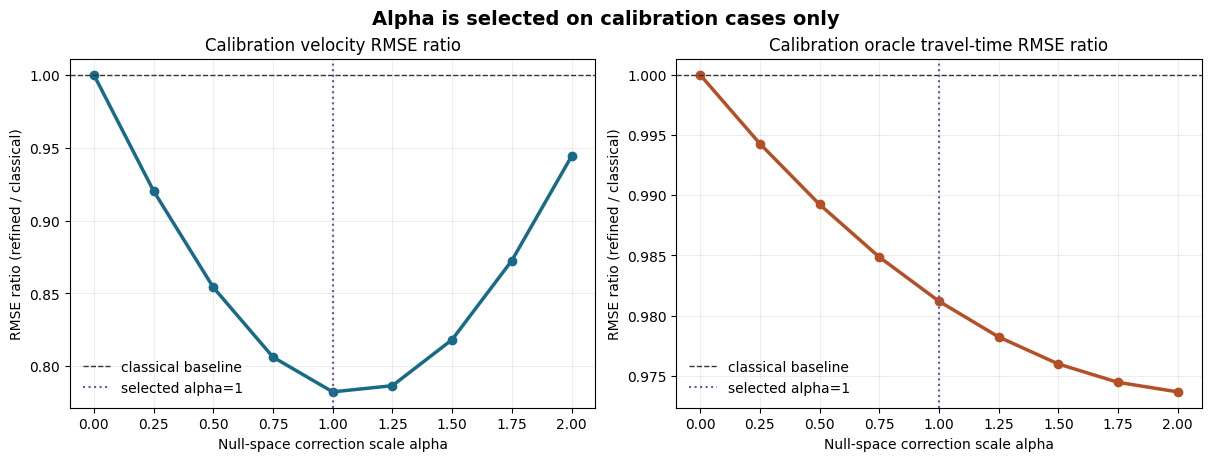

Selection rule: True — both metrics must improve; then minimize their mean ratio.


In [2]:
# Reproducible analysis cell.
# Plot the recorded calibration-only selection grid; do not inspect test outcomes for selection.
selection=analysis["calibration_selection"]
grid=selection["grid"]
alpha=np.array(sorted(float(x) for x in grid))
velocity=np.array([grid[str(x)]["velocity_ratio"] for x in alpha])
time=np.array([grid[str(x)]["oracle_time_ratio"] for x in alpha])
fig,ax=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
for axis,values,title,color in ((ax[0],velocity,"Calibration velocity RMSE ratio","#176b87"),(ax[1],time,"Calibration oracle travel-time RMSE ratio","#b54f27")):
    axis.plot(alpha,values,"o-",lw=2.5,color=color)
    axis.axhline(1,color="#30343b",lw=1,ls="--",label="classical baseline")
    axis.axvline(selection["selected_alpha"],color="#7353a6",lw=1.5,ls=":",label=f"selected alpha={selection['selected_alpha']:g}")
    axis.set(xlabel="Null-space correction scale alpha",ylabel="RMSE ratio (refined / classical)",title=title)
    axis.grid(alpha=.22); axis.legend(frameon=False)
fig.suptitle("Alpha is selected on calibration cases only",fontsize=14,fontweight="bold")
plt.show()
print("Selection rule:", selection["calibration_supported"], "— both metrics must improve; then minimize their mean ratio.")

### Experiment 3 — Inspect paired case outcomes

Edit `cohort_to_inspect` to examine the other fixed cohort. Each dot is one matched synthetic realization. Values below one indicate improvement over the classical baseline for that metric.

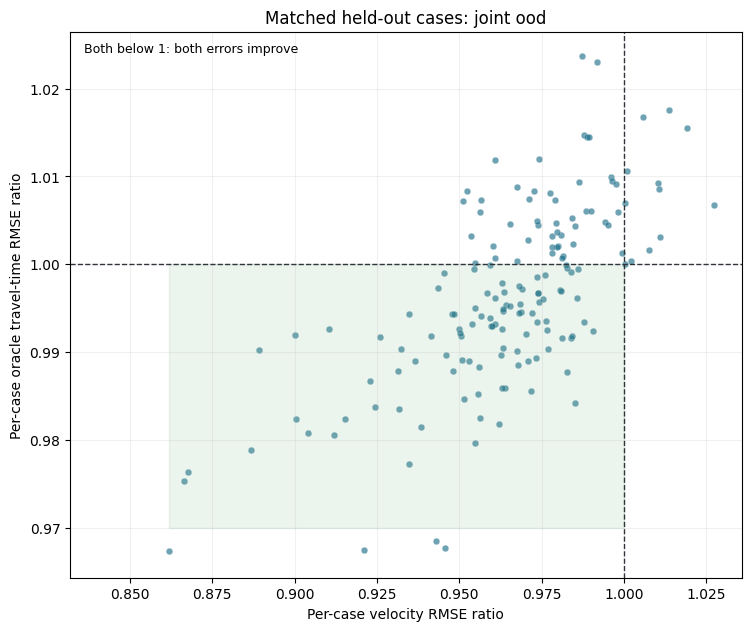

Median ratios: velocity=0.9683 oracle-time=0.9962
Cases improving both: 100 of 160
These are per-realization ratios inside one synthetic generator, not uncertainty across geology.


In [3]:
# Reproducible analysis cell.
cohort_to_inspect="joint_ood"  # Change to id_test, family_only or acquisition_only and rerun this cell.
row=analysis["cohorts"][cohort_to_inspect]
x=np.asarray(row["velocity"]["case_ratios"],float)
y=np.asarray(row["oracle_time"]["case_ratios"],float)
fig,ax=plt.subplots(figsize=(7.4,6.2),constrained_layout=True)
ax.scatter(x,y,s=23,alpha=.62,c="#176b87",edgecolors="white",linewidths=.25)
ax.axvline(1,color="#30343b",lw=1,ls="--"); ax.axhline(1,color="#30343b",lw=1,ls="--")
ax.fill_between([max(.5,float(x.min())),1],[max(.97,float(y.min()))]*2,[1,1],color="#64a77b",alpha=.12)
ax.set(xlabel="Per-case velocity RMSE ratio",ylabel="Per-case oracle travel-time RMSE ratio",title=f"Matched held-out cases: {cohort_to_inspect.replace('_',' ')}")
ax.grid(alpha=.18); ax.set_xlim(left=max(.5,float(x.min())-.03)); ax.set_ylim(bottom=min(.97,float(y.min())-.003))
ax.text(.02,.98,"Both below 1: both errors improve",transform=ax.transAxes,va="top",fontsize=9)
plt.show()
print("Median ratios:",f"velocity={np.median(x):.4f}",f"oracle-time={np.median(y):.4f}")
print("Cases improving both:",int(np.sum((x<1)&(y<1))),"of",len(x))
print("These are per-realization ratios inside one synthetic generator, not uncertainty across geology.")